In [1]:
import torch
import pandas as pd
import numpy as np
import sys
import os
from pathlib import Path
from torch_geometric.loader import DataLoader
from sklearn.decomposition import PCA
from scipy.spatial.distance import pdist
from scipy.spatial import procrustes
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from torch_geometric.nn import global_mean_pool
sys.path.append(str(Path.cwd().parent))
from configs.config import HARMONIZED_DATA_PATH
molclr_path = os.path.abspath('../MolCLR')
if molclr_path not in sys.path:
    sys.path.append(molclr_path)
from models.gcn_molclr import GCN
from gnn_models_utils import (
    smiles_to_graph,
    GCNDrugEncoder,
    GATDrugEncoder,
    GINDrugEncoder
)

device = torch.device("cuda" if torch.cuda.is_available() else "mps")
node_feature_dim = 4
hidden_dim = 64
batch_size = 10

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
df = pd.read_parquet(HARMONIZED_DATA_PATH)

In [17]:
unique_df = df.dropna(subset=['SMILES']).drop_duplicates(subset=['SMILES']).head(10).reset_index(drop=True)
mfp_cols = [col for col in unique_df.columns if str(col).startswith('Bit_')]

real_graphs = []
valid_indices = []

for idx, s in enumerate(unique_df['SMILES'].values):
    g = smiles_to_graph(s)
    if g is not None:
        real_graphs.append(g)
        valid_indices.append(idx)
real_loader = DataLoader(real_graphs, batch_size=len(real_graphs), shuffle=False)
batch = next(iter(real_loader)).to(device)

X_morgan = unique_df.loc[valid_indices, mfp_cols].values.astype(np.float32)

node_feature_dim = batch.x.shape[1]
hidden_dim = 64

## Verify forward pass

In [10]:
def verify_forward_pass(model, batch, expected_hidden_dim, model_name):
    model = model.to(device).eval()
    with torch.no_grad():
        node_embeddings, graph_embeddings = model(batch)

    expected_node_shape = (batch.x.shape[0], expected_hidden_dim)
    expected_graph_shape = (batch.num_graphs, expected_hidden_dim)
    assert node_embeddings.shape == expected_node_shape, (
        f"Expected node shape {expected_node_shape}, got {node_embeddings.shape}"
    )
    assert graph_embeddings.shape == expected_graph_shape, (
        f"Expected graph shape {expected_graph_shape}, got {graph_embeddings.shape}"
    )
    assert torch.isfinite(node_embeddings).all(), "Node embeddings contain NaN or Inf values"
    assert torch.isfinite(graph_embeddings).all(), "Graph embeddings contain NaN or Inf values"

    print(f"[OK] {model_name}: Forward pass successful!")
    print(f"     Node embeddings: {node_embeddings.shape} | Graph embeddings: {graph_embeddings.shape}\n")

In [18]:
gcn_model = GCNDrugEncoder(node_feature_dim=node_feature_dim, hidden_dim=hidden_dim, dropout=0.1)
gin_model = GINDrugEncoder(node_feature_dim=node_feature_dim, hidden_dim=hidden_dim, dropout=0.1)
gat_model = GATDrugEncoder(node_feature_dim=node_feature_dim, hidden_dim=hidden_dim, dropout=0.1)
verify_forward_pass(gcn_model, batch, hidden_dim, "GCNDrugEncoder (Real data)")
verify_forward_pass(gin_model, batch, hidden_dim, "GINDrugEncoder (Real data)")
verify_forward_pass(gat_model, batch, hidden_dim, "GATDrugEncoder (Real data)")

print(f"Test batch created on{device}:")
print(f"  - Number of graphs in the batch: {batch.num_graphs}")
print(f"  - Total number of atoms (nodes): {batch.x.shape[0]}")
print(f"  - Input Shape (x): {batch.x.shape}")
print(f"  - Edge Index Shape: {batch.edge_index.shape}\n")

[OK] GCNDrugEncoder (Real data): Forward pass successful!
     Node embeddings: torch.Size([246, 64]) | Graph embeddings: torch.Size([10, 64])

[OK] GINDrugEncoder (Real data): Forward pass successful!
     Node embeddings: torch.Size([246, 64]) | Graph embeddings: torch.Size([10, 64])

[OK] GATDrugEncoder (Real data): Forward pass successful!
     Node embeddings: torch.Size([246, 64]) | Graph embeddings: torch.Size([10, 64])

Test batch created onmps:
  - Number of graphs in the batch: 10
  - Total number of atoms (nodes): 246
  - Input Shape (x): torch.Size([246, 2])
  - Edge Index Shape: torch.Size([2, 516])



## Embed drug encoding into latent space

Extract graph-level embeddings for all models

In [19]:
@torch.no_grad()
def get_custom_gnn_embeddings(model, batch):
    model = model.to(device).eval()
    node_emb, graph_emb = model(batch)
    # Pooling from the atomic level [num_atoms, hidden_dim] to the molecular level [10, hidden_dim]
    #graph_emb = global_mean_pool(node_emb, batch.batch)
    return graph_emb.cpu().numpy()

@torch.no_grad()
def get_molclr_embeddings(molclr_model, batch):
    molclr_model = molclr_model.to(device).eval()
    # Create a copy & safely clean it up for MolCLR embeddings
    b = batch.clone()
    b.x = b.x.long()
    b.edge_attr = b.edge_attr.long()
    b.x[:, 0] = torch.clamp(b.x[:, 0], min=0, max=119)
    b.x[:, 1] = torch.clamp(b.x[:, 1], min=0, max=2)
    b.edge_attr[:, 0] = torch.clamp(b.edge_attr[:, 0], min=0, max=3)
    b.edge_attr[:, 1] = torch.clamp(b.edge_attr[:, 1], min=0, max=2)
    
    _, h_mol = molclr_model(b)
    return h_mol.cpu().numpy()

In [20]:
gcn = GCNDrugEncoder(node_feature_dim=node_feature_dim, hidden_dim=64)
gin = GINDrugEncoder(node_feature_dim=node_feature_dim, hidden_dim=64)
gat = GATDrugEncoder(node_feature_dim=node_feature_dim, hidden_dim=64)
molclr_gcn = GCN(num_layer=5, emb_dim=300, feat_dim=512, drop_ratio=0, pool="mean").to(device)
molclr_dir = Path("../MolCLR").resolve()
checkpoint_path = molclr_dir / "ckpt" / "pretrained_gcn" / "checkpoints" / "model.pth"
state_dict = torch.load(checkpoint_path, map_location=device, weights_only=True)
molclr_gcn.load_state_dict(state_dict, strict=True)

embeddings = {
    "GCN": get_custom_gnn_embeddings(gcn, batch),
    "GIN": get_custom_gnn_embeddings(gin, batch),
    "GAT": get_custom_gnn_embeddings(gat, batch),
    "MolCLR (Pre-trained)": get_molclr_embeddings(molclr_gcn, batch)
}

Model                  | Procrustes Disparity (↓)         | Distance-Correlation (Spearman ↑)
------------------------------------------------------------------------------------------
GCN                    | 0.9516                           | -0.1741
GIN                    | 0.9439                           | -0.2196
GAT                    | 0.8994                           | -0.2791
MolCLR (Pre-trained)   | 0.6107                           | -0.1887


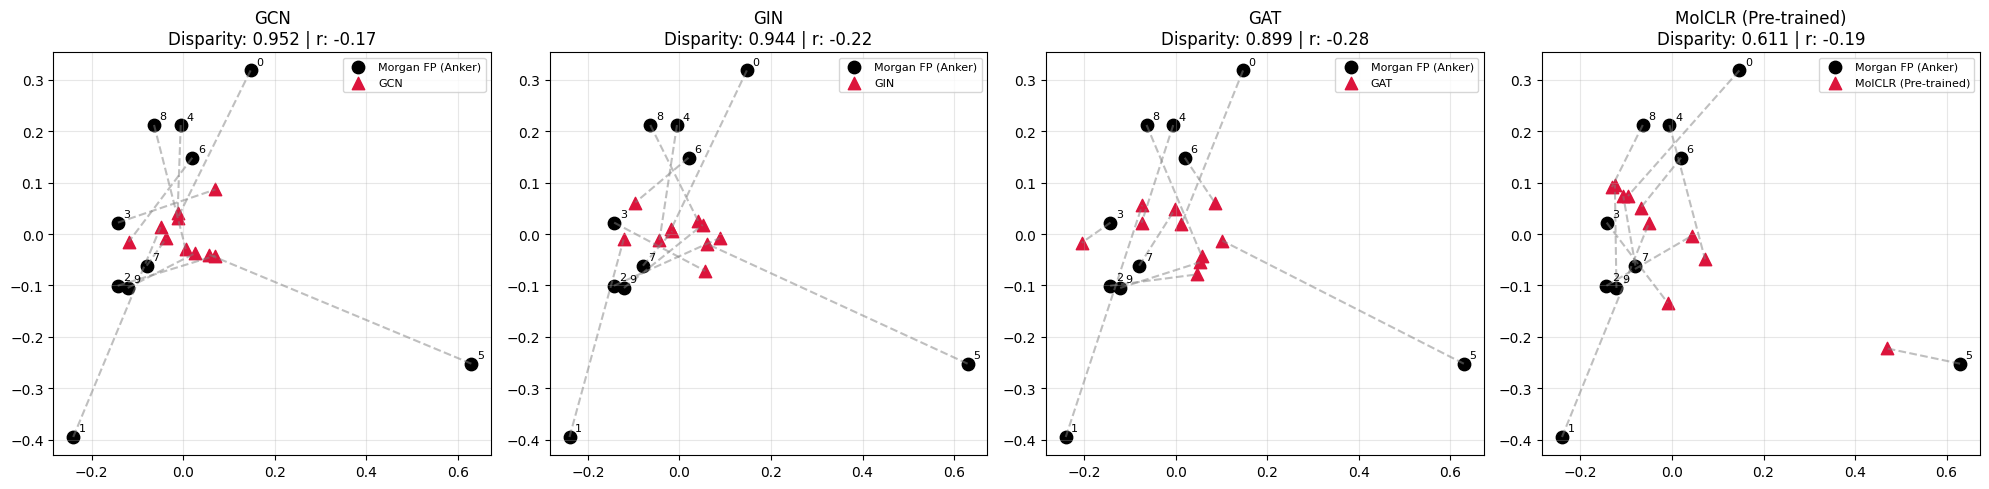

In [21]:
pca = PCA(n_components=2, random_state=42)
anchor_2d = pca.fit_transform(X_morgan)
anchor_dists = pdist(X_morgan, metric='cosine')

fig, axes = plt.subplots(1, len(embeddings), figsize=(5 * len(embeddings), 5))
if len(embeddings) == 1:
    axes = [axes]

print(f"{'Model':<22} | {'Procrustes Disparity (↓)':<32} | {'Distance-Correlation (Spearman ↑)'}")
print("-" * 90)

for ax, (name, emb) in zip(axes, embeddings.items()):
    # Reduce GNN embedding to 2D
    gnn_2d = PCA(n_components=2, random_state=42).fit_transform(emb)
    
    # Align with the Morgan Anchor (Procrustes)
    mtx_anchor, mtx_gnn, disparity = procrustes(anchor_2d, gnn_2d)
    
    # Calculate the quantitative similarity of pairwise distances
    gnn_dists = pdist(emb, metric='cosine')
    corr, _ = spearmanr(anchor_dists, gnn_dists)
    print(f"{name:<22} | {disparity:<32.4f} | {corr:.4f}")
    
    # Plotting in a Shared Latent Space
    ax.scatter(mtx_anchor[:, 0], mtx_anchor[:, 1], c='black', marker='o', s=80, label='Morgan FP (Anker)')
    ax.scatter(mtx_gnn[:, 0], mtx_gnn[:, 1], c='crimson', marker='^', s=80, label=name)
    
    # Connecting lines between the anchor and the GNN position for each molecule
    for i in range(len(mtx_anchor)):
        ax.plot([mtx_anchor[i, 0], mtx_gnn[i, 0]], 
                [mtx_anchor[i, 1], mtx_gnn[i, 1]], 
                color='gray', linestyle='--', alpha=0.5)
        ax.annotate(str(i), (mtx_anchor[i, 0], mtx_anchor[i, 1]), fontsize=8, xytext=(4, 4), textcoords='offset points')
        
    ax.set_title(f"{name}\nDisparity: {disparity:.3f} | r: {corr:.2f}")
    ax.legend(loc='best', fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

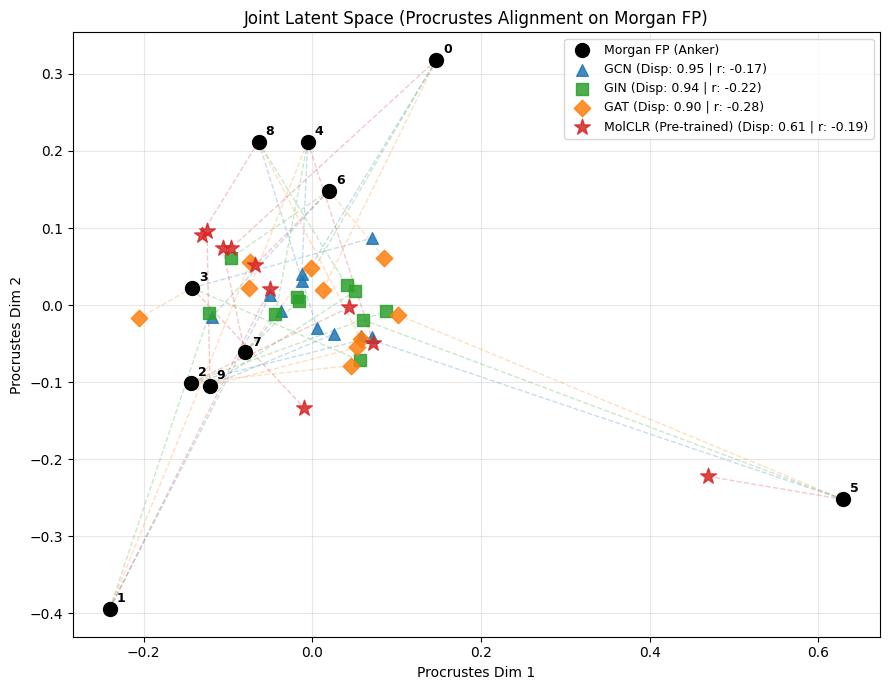

In [24]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.spatial import procrustes
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

# 1. Anker auf 2D reduzieren
anchor_2d = PCA(n_components=2, random_state=42).fit_transform(X_morgan)
anchor_dists = pdist(X_morgan, metric='cosine')

# Farben & Marker pro Modell definieren
styles = {
    "GCN":                  {"color": "#1f77b4", "marker": "^"},  # Blau, Dreieck
    "GIN":                  {"color": "#2ca02c", "marker": "s"},  # Grün, Quadrat
    "GAT":                  {"color": "#ff7f0e", "marker": "D"},  # Orange, Raute
    "MolCLR (Pre-trained)": {"color": "#d62728", "marker": "*"},  # Rot, Stern
}

fig, ax = plt.subplots(figsize=(9, 7))
anchor_plotted = False

for name, emb in embeddings.items():
    # GNN auf 2D reduzieren & auf Anker ausrichten
    gnn_2d = PCA(n_components=2, random_state=42).fit_transform(emb)
    mtx_anchor, mtx_gnn, disparity = procrustes(anchor_2d, gnn_2d)
    
    # Spearman-Korrelation berechnen
    corr, _ = spearmanr(anchor_dists, pdist(emb, metric='cosine'))
    
    # Anker nur einmal plotten
    if not anchor_plotted:
        ax.scatter(mtx_anchor[:, 0], mtx_anchor[:, 1], 
                   c='black', marker='o', s=100, zorder=5, label='Morgan FP (Anker)')
        for i in range(len(mtx_anchor)):
            ax.annotate(str(i), (mtx_anchor[i, 0], mtx_anchor[i, 1]), 
                        fontsize=9, fontweight='bold', xytext=(5, 5), textcoords='offset points')
        anchor_plotted = True

    style = styles.get(name, {"color": "purple", "marker": "x"})
    size = 140 if "MolCLR" in name else 70  # MolCLR leicht hervorheben

    # GNN-Punkte plotten (inkl. Disparity in der Legende)
    ax.scatter(mtx_gnn[:, 0], mtx_gnn[:, 1], 
               c=style["color"], marker=style["marker"], s=size, alpha=0.85, zorder=4,
               label=f"{name} (Disp: {disparity:.2f} | r: {corr:.2f})")

    # Dezente Verbindungslinien zum Anker
    for i in range(len(mtx_anchor)):
        ax.plot([mtx_anchor[i, 0], mtx_gnn[i, 0]], 
                [mtx_anchor[i, 1], mtx_gnn[i, 1]], 
                color=style["color"], linestyle='--', alpha=0.25, linewidth=1, zorder=2)

ax.set_title("Joint Latent Space (Procrustes Alignment on Morgan FP)", fontsize=12)
ax.set_xlabel("Procrustes Dim 1")
ax.set_ylabel("Procrustes Dim 2")
ax.legend(loc='best', fontsize=9, frameon=True)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()